In [1]:
import pandas as pd
import numpy as np
import pandas as pa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [2]:
## load the dataset

In [3]:
df = pa.read_csv("heart.csv")

In [4]:
## Data exploration

In [5]:
## Displays the first five rows

In [6]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [7]:
df['age'].min()

29

In [8]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [9]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [10]:
## Dimension of the dataset

In [11]:
df.shape

(1025, 14)

In [12]:
print(len(df))

1025


In [13]:
## Displays the dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [14]:
## Summary statistics

In [15]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [16]:
## data cleaning

In [17]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [18]:
## Check for duplicates
df.duplicated().sum()

np.int64(723)

In [19]:
## outlier Detection using IQR method

In [20]:
for col in df.select_dtypes(include="number").columns:
    Q1 =df[col].quantile(0.25)
    Q3 =df[col].quantile(0.75)
    IQR = Q3-Q1

In [21]:
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR

In [22]:
outliers = df[(df[col]<lower_bound) | (df[col]>upper_bound)]

In [23]:
print(len(outliers))

0


In [24]:
## Declare the variables

In [25]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [26]:
x = df[['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal']]
y = df['target']

In [27]:
x.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2


In [28]:
x.shape

(1025, 13)

In [29]:
y.shape

(1025,)

In [30]:
## splitting the dataset
from sklearn.model_selection import train_test_split

In [31]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [32]:
x_train.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
835,49,1,2,118,149,0,0,126,0,0.8,2,3,2
137,64,0,0,180,325,0,1,154,1,0.0,2,0,2
534,54,0,2,108,267,0,0,167,0,0.0,2,0,2
495,59,1,0,135,234,0,1,161,0,0.5,1,0,3
244,51,1,2,125,245,1,0,166,0,2.4,1,0,2


In [33]:
x_train.shape

(820, 13)

In [34]:
y_train.shape

(820,)

In [35]:
## create the model

In [36]:
model1 =LogisticRegression()

In [37]:
import warnings
warnings.filterwarnings("ignore")

In [38]:
model1.fit(x_train, y_train)

LogisticRegression()

In [39]:
y_pred_lr = model1.predict(x_test)
y_pred_lr

array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 0, 0])

In [40]:
## model evaluation

In [41]:
print(accuracy_score(y_test, y_pred_lr))

0.7804878048780488


In [42]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.84      0.69      0.76       102
           1       0.74      0.87      0.80       103

    accuracy                           0.78       205
   macro avg       0.79      0.78      0.78       205
weighted avg       0.79      0.78      0.78       205



In [43]:
cm = confusion_matrix(y_test, y_pred_lr)
cm

array([[70, 32],
       [13, 90]])

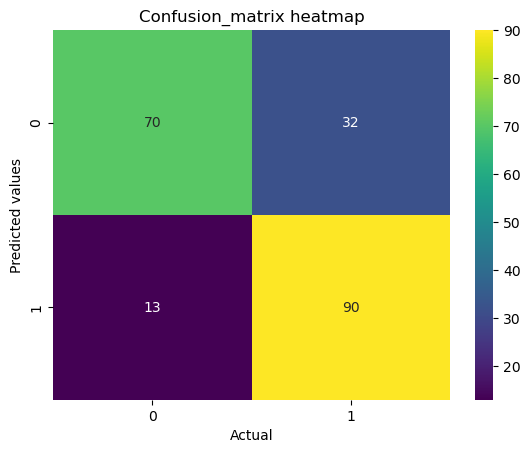

In [44]:
sns.heatmap(cm, annot=True, cmap="viridis")
plt.title("Confusion_matrix heatmap")
plt.xlabel("Actual")
plt.ylabel("Predicted values")
plt.show()

In [45]:
### DECISION TREE MODEL

In [46]:
model2 = DecisionTreeClassifier()

In [47]:
model2.fit(x_train, y_train)

DecisionTreeClassifier()

In [48]:
y_pred_dt = model2.predict(x_test)

In [49]:
### RANDOMFOREST CLASSIFIER

In [50]:
model3 = RandomForestClassifier()

In [51]:
model3.fit(x_train, y_train)

RandomForestClassifier()

In [52]:
y_pred_rf = model3.predict(x_test)

In [53]:
importances_df = pd.DataFrame({
    'Feature' :x.columns,
    'importance': model2.feature_importances_
}).sort_values(by='importance', ascending=True)
print(importances_df)

     Feature  importance
6    restecg    0.006511
5        fbs    0.008371
8      exang    0.018866
1        sex    0.026434
10     slope    0.042835
0        age    0.056274
3   trestbps    0.057462
7    thalach    0.065777
4       chol    0.081357
9    oldpeak    0.095549
11        ca    0.118901
12      thal    0.147141
2         cp    0.274524


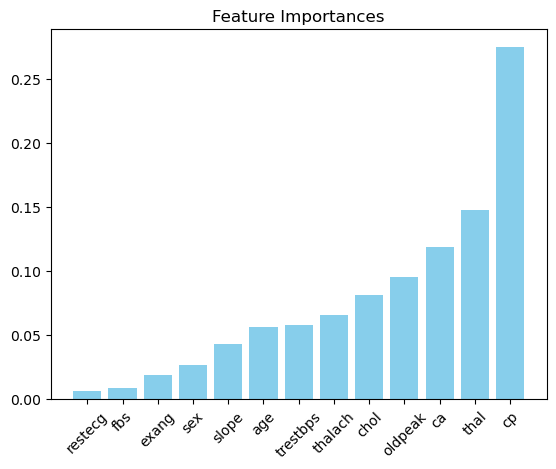

In [54]:
plt.bar(importances_df['Feature'], importances_df['importance'], color="skyblue")
plt.title("Feature Importances")
plt.xticks(rotation=45)
plt.show()

In [55]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [56]:
## MODEL PERFORMANCE COMPARISION

In [57]:
def calculate_metrics(y_true, y_pred, model_name):
    return{
        'Model Name':model_name,
        'Accuracy':f"{accuracy_score(y_true, y_pred)*100:.2f}%",
        'Recall (macro)': f"{recall_score(y_true, y_pred, average="macro")*100:.2f}%",
        'F1-score (macro)': f"{f1_score(y_true, y_pred, average='macro')*100:.2f}",
    }

summary_df = pd.DataFrame([
    calculate_metrics(y_test,y_pred_lr, 'LogisticRegression'),
    calculate_metrics(y_test, y_pred_dt, 'DecisionTreeClassifier'),
    calculate_metrics(y_test, y_pred_rf, 'RandomForestClassifier')
])

In [58]:
print("MODEL PERFOMANCE COMPARISION METRICS")
print(summary_df.to_string(index=False))

MODEL PERFOMANCE COMPARISION METRICS
            Model Name Accuracy Recall (macro) F1-score (macro)
    LogisticRegression   78.05%         78.00%            77.84
DecisionTreeClassifier   98.54%         98.54%            98.54
RandomForestClassifier   98.54%         98.54%            98.54


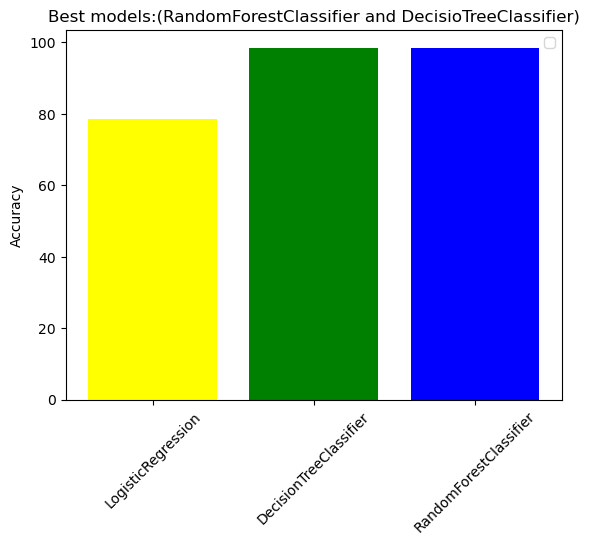

In [59]:
models= ['LogisticRegression','DecisionTreeClassifier','RandomForestClassifier']
Accuracy = [78.54, 98.54,98.54]
plt.bar(models, Accuracy, color=['yellow', 'green', 'blue'])
plt.title('Best models:(RandomForestClassifier and DecisioTreeClassifier)')
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [60]:
## visaual comparision

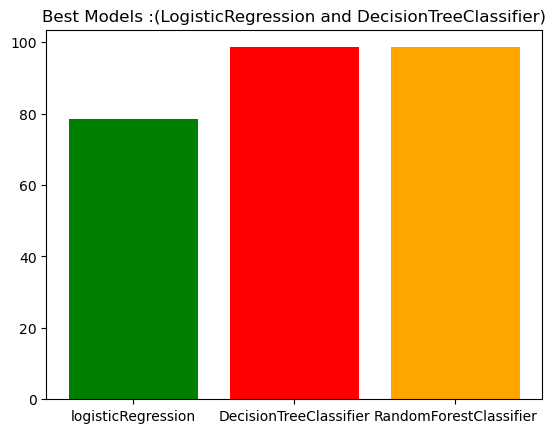

In [61]:
models =['logisticRegression', 'DecisionTreeClassifier','RandomForestClassifier']
Accuracy =[78.54, 98.54, 98.54]
plt.bar(models, Accuracy,color=['green', 'red', 'orange'])
plt.title("Best Models :(LogisticRegression and DecisionTreeClassifier)")
plt.show()

In [62]:
## model deployment

In [63]:
import joblib

In [64]:
joblib.dump(model3, "Heart_Diesease_prediction.joblib")

['Heart_Diesease_prediction.joblib']

In [65]:
!pip install streamlit

In [ ]:
!streamlit run app.py